In [89]:
#Setup cell — add project root to path

import sys
from pathlib import Path

# Make `ml` importable whether Jupyter is launched from root or notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)



Project root: c:\football_platform


In [90]:
import warnings
warnings.filterwarnings("ignore")

import ast
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ml import data_loader

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")

In [91]:
# Inventory of seasons and files

seasons = data_loader.list_seasons()
print(f"Seasons found: {len(seasons)}")
for s in seasons:
    print(" -", s)

inventory = pd.DataFrame(
    {s: data_loader.file_inventory(s) for s in seasons}
).T
inventory

Seasons found: 7
 - 2020-21
 - 2021-22
 - 2022-23
 - 2023-24
 - 2024-25
 - 2025-26
 - 2026-27


,e0,gameweeks,player_gw,player_history,understat,xp
2020-21,True,True,True,True,True,True
2021-22,True,True,True,True,True,True
2022-23,True,True,True,True,True,True
2023-24,True,True,True,True,True,True
2024-25,True,True,True,True,True,True
2025-26,True,True,True,True,False,True
2026-27,True,True,True,True,False,True


#§2 — E0 match data

In [92]:
#§2 — E0 match data
e0 = data_loader.load_e0("2020-21")
print("shape:", e0.shape)
print("\ncolumns (first 20):")
print(e0.columns.tolist()[:20], "...")
print("\ndtypes:")
print(e0.dtypes.value_counts())
e0.head(3)


shape: (380, 107)

columns (first 20):
['Division', 'Match_Date', 'Kickoff_Time', 'Home_Team', 'Away_Team', 'Full_Time_Home_Goals', 'Full_Time_Away_Goals', 'Full_Time_Result', 'Half_Time_Home_Goals', 'Half_Time_Away_Goals', 'Half_Time_Result', 'Referee', 'Home_Shots', 'Away_Shots', 'Home_Shots_On_Target', 'Away_Shots_On_Target', 'Home_Fouls', 'Away_Fouls', 'Home_Corners', 'Away_Corners'] ...

dtypes:
float64    82
int64      16
str         9
Name: count, dtype: int64


,Division,Match_Date,Kickoff_Time,Home_Team,Away_Team,Full_Time_Home_Goals,Full_Time_Away_Goals,Full_Time_Result,Half_Time_Home_Goals,Half_Time_Away_Goals,Half_Time_Result,Referee,Home_Shots,Away_Shots,Home_Shots_On_Target,Away_Shots_On_Target,Home_Fouls,Away_Fouls,Home_Corners,Away_Corners,Home_Yellow_Cards,Away_Yellow_Cards,Home_Red_Cards,Away_Red_Cards,Bet365_Home_Odds,Bet365_Draw_Odds,Bet365_Away_Odds,Betway_Home_Odds,Betway_Draw_Odds,Betway_Away_Odds,IWH,IWD,IWA,Pinnacle_Home_Odds,Pinnacle_Draw_Odds,Pinnacle_Away_Odds,WHH,WHD,WHA,VCH,VCD,VCA,Max_Market_Home_Odds,Max_Market_Draw_Odds,Max_Market_Away_Odds,Avg_Market_Home_Odds,Avg_Market_Draw_Odds,Avg_Market_Away_Odds,Bet365_Over_2.5_Goals,Bet365_Under_2.5_Goals,Pinnacle_Over_2.5_Goals,Pinnacle_Under_2.5_Goals,Max_Over_2.5_Goals,Max_Under_2.5_Goals,Avg_Over_2.5_Goals,Avg_Under_2.5_Goals,Asian_Handicap_Size,Bet365_Asian_Handicap_Home,Bet365_Asian_Handicap_Away,Pinnacle_Asian_Handicap_Home,Pinnacle_Asian_Handicap_Away,Max_Asian_Handicap_Home,Max_Asian_Handicap_Away,Avg_Asian_Handicap_Home,Avg_Asian_Handicap_Away,Bet365_Closing_Home_Odds,Bet365_Closing_Draw_Odds,Bet365_Closing_Away_Odds,Betway_Closing_Home_Odds,Betway_Closing_Draw_Odds,Betway_Closing_Away_Odds,IWCH,IWCD,IWCA,Pinnacle_Closing_Home_Odds,Pinnacle_Closing_Draw_Odds,Pinnacle_Closing_Away_Odds,WHCH,WHCD,WHCA,VCCH,VCCD,VCCA,Max_Closing_Home_Odds,Max_Closing_Draw_Odds,Max_Closing_Away_Odds,Avg_Closing_Home_Odds,Avg_Closing_Draw_Odds,Avg_Closing_Away_Odds,Bet365_Closing_Over_2.5,Bet365_Closing_Under_2.5,Pinnacle_Closing_Over_2.5,Pinnacle_Closing_Under_2.5,Max_Closing_Over_2.5,Max_Closing_Under_2.5,Avg_Closing_Over_2.5,Avg_Closing_Under_2.5,Closing_Asian_Handicap_Size,Bet365_Closing_Asian_Handicap_Home,Bet365_Closing_Asian_Handicap_Away,Pinnacle_Closing_Asian_Handicap_Home,Pinnacle_Closing_Asian_Handicap_Away,Max_Closing_Asian_Handicap_Home,Max_Closing_Asian_Handicap_Away,Avg_Closing_Asian_Handicap_Home,Avg_Closing_Asian_Handicap_Away,season
0,E0,12/09/2020,12:30,Fulham,Arsenal,0,3,A,0,1,A,C Kavanagh,5,13,2,6,12,12,2,3,2,2,0,0,6.000,4.330,1.530,5.500,4.250,1.570,6.000,3.900,1.570,6.160,4.510,1.560,6.500,4.200,1.530,6.500,4.200,1.550,6.550,4.550,1.600,5.940,4.340,1.550,1.720,2.100,1.800,2.130,1.840,2.180,1.760,2.100,1.000,1.930,1.970,1.960,1.960,2.000,1.990,1.930,1.950,5.000,4.000,1.660,5.500,4.000,1.620,5.250,3.900,1.670,5.480,3.980,1.690,5.500,3.800,1.650,5.500,3.900,1.670,5.750,4.200,1.710,5.360,3.930,1.670,2.000,1.800,2.060,1.860,2.100,1.920,2.000,1.840,0.750,2.010,1.890,2.020,1.910,2.130,1.920,2.020,1.870,2020-21
1,E0,12/09/2020,15:00,Crystal Palace,Southampton,1,0,H,1,0,H,J Moss,5,9,3,5,14,11,7,3,2,1,0,0,3.100,3.250,2.370,3.000,3.200,2.450,3.150,2.950,2.400,3.320,3.290,2.400,3.200,3.200,2.350,3.200,3.200,2.400,3.360,3.360,2.500,3.180,3.220,2.390,2.200,1.660,2.340,1.680,2.360,1.730,2.240,1.670,0.250,1.850,2.050,1.880,2.050,1.880,2.070,1.840,2.030,3.000,3.250,2.400,3.000,3.300,2.400,3.050,2.900,2.450,3.090,3.270,2.540,3.100,3.100,2.450,3.100,3.250,2.450,3.250,3.330,2.550,3.080,3.220,2.470,2.200,1.660,2.260,1.720,2.270,1.780,2.180,1.700,0.250,1.780,2.130,1.790,2.170,1.850,2.180,1.790,2.120,2020-21
2,E0,12/09/2020,17:30,Liverpool,Leeds,4,3,H,3,2,H,M Oliver,22,6,6,3,9,6,9,0,1,0,0,0,1.280,6.000,9.500,1.260,6.250,10.500,1.350,5.000,8.500,1.310,6.250,9.920,1.270,6.000,10.000,1.300,5.750,10.500,1.350,6.500,10.750,1.300,5.960,9.680,1.530,2.500,1.560,2.600,1.560,2.680,1.520,2.530,-1.500,1.950,1.950,1.970,1.950,2.000,2.080,1.900,1.970,1.250,6.000,11.000,1.250,6.250,11.000,1.300,6.000,9.000,1.280,6.340,11.380,1.250,6.000,12.000,1.290,6.000,11.500,1.300,6.750,12.270,1.280,6.160,10.630,1.500,2.620,1.510,2.760,1.530,2.820,1.500,2.620,-1.500,1.850,2.050,1.850,2.080,1.900,2.160,1.840,2.040,2020-21


In [93]:
print("=== Missing values (top 20 columns) ===")
(e0.isna().sum() / len(e0)).sort_values(ascending=False).head(20)

=== Missing values (top 20 columns) ===


Division               0.000
Match_Date             0.000
Kickoff_Time           0.000
Home_Team              0.000
Away_Team              0.000
Full_Time_Home_Goals   0.000
Full_Time_Away_Goals   0.000
Full_Time_Result       0.000
Half_Time_Home_Goals   0.000
Half_Time_Away_Goals   0.000
Half_Time_Result       0.000
Referee                0.000
Home_Shots             0.000
Away_Shots             0.000
Home_Shots_On_Target   0.000
Away_Shots_On_Target   0.000
Home_Fouls             0.000
Away_Fouls             0.000
Home_Corners           0.000
Away_Corners           0.000
dtype: float64

In [94]:
# Match count per season — must be 380 for a complete EPL season
rows = []
for s in seasons:
    df = data_loader.load_e0(s)
    if df is None:
        rows.append({"season": s, "matches": None, "columns": None})
        continue
    rows.append({
        "season": s,
        "matches": len(df),
        "columns": df.shape[1],
        "date_min": df["Match_Date"].iloc[0] if len(df) else None,
        "date_max": df["Match_Date"].iloc[-1] if len(df) else None,
    })
pd.DataFrame(rows)

,season,matches,columns,date_min,date_max
0,2020-21,380,107,12/09/2020,23/05/2021
1,2021-22,380,107,13/08/2021,22/05/2022
2,2022-23,380,107,05/08/2022,28/05/2023
3,2023-24,380,107,11/08/2023,19/05/2024
4,2024-25,380,121,16/08/2024,25/05/2025
5,2025-26,380,133,15/08/2025,24/05/2026
6,2026-27,70,115,21/08/2026,19/10/2026


In [95]:
# Column set stability across seasons
col_sets = {}
for s in seasons:
    df = data_loader.load_e0(s)
    if df is not None:
        col_sets[s] = set(df.columns) - {"season"}

reference = col_sets[seasons[0]]
for s, cols in col_sets.items():
    added = cols - reference
    removed = reference - cols
    if added or removed:
        print(f"{s}: +{sorted(added)} / -{sorted(removed)}")
    else:
        print(f"{s}: identical to {seasons[0]}")

2020-21: identical to 2020-21
2021-22: identical to 2020-21
2022-23: identical to 2020-21
2023-24: identical to 2020-21
2024-25: +['1XBA', '1XBCA', '1XBCD', '1XBCH', '1XBD', '1XBH', 'BFA', 'BFCA', 'BFCD', 'BFCH', 'BFD', 'BFH', 'BetfairExchange_Asian_Handicap_Away', 'BetfairExchange_Asian_Handicap_Home', 'BetfairExchange_Away_Odds', 'BetfairExchange_Closing_Asian_Handicap_Away', 'BetfairExchange_Closing_Asian_Handicap_Home', 'BetfairExchange_Closing_Away_Odds', 'BetfairExchange_Closing_Draw_Odds', 'BetfairExchange_Closing_Home_Odds', 'BetfairExchange_Closing_Over_2.5', 'BetfairExchange_Closing_Under_2.5', 'BetfairExchange_Draw_Odds', 'BetfairExchange_Home_Odds', 'BetfairExchange_Over_2.5_Goals', 'BetfairExchange_Under_2.5_Goals'] / -['IWA', 'IWCA', 'IWCD', 'IWCH', 'IWD', 'IWH', 'VCA', 'VCCA', 'VCCD', 'VCCH', 'VCD', 'VCH']
2025-26: +['BetMGM_Away_Odds', 'BetMGM_Closing_Away_Odds', 'BetMGM_Closing_Draw_Odds', 'BetMGM_Closing_Home_Odds', 'BetMGM_Draw_Odds', 'BetMGM_Home_Odds', 'BetVictor_A

§3 — Player gameweek data

In [96]:
gw = data_loader.load_gameweeks("2020-21")
pgw = data_loader.load_player_gw("2020-21")

print("gameweeks:", gw.shape)
print("player_gw:", pgw.shape)
print("\ncolumns in gameweeks but not player_gw:",
      sorted(set(gw.columns) - set(pgw.columns) - {"season"}))
print("columns in player_gw but not gameweeks:",
      sorted(set(pgw.columns) - set(gw.columns) - {"season"}))

gameweeks: (24365, 36)
player_gw: (24365, 33)

columns in gameweeks but not player_gw: ['name', 'position', 'team', 'xP']
columns in player_gw but not gameweeks: ['player_folder_name']


In [97]:
# Duplicate check — one row per (element, fixture)
dups = pgw.duplicated(subset=["element", "fixture"]).sum()
print(f"Duplicate (element, fixture) rows: {dups}")

# Positions present
print("\nPositions:", pgw["position"].unique() if "position" in pgw else
      gw["position"].unique())

# was_home raw values
print("\nwas_home dtype/values:", gw["was_home"].dtype, gw["was_home"].unique())

Duplicate (element, fixture) rows: 0

Positions: <StringArray>
['FWD', 'DEF', 'MID', 'GK']
Length: 4, dtype: str

was_home dtype/values: bool [ True False]


In [98]:
# Row count per season — should be ≈ 700-800 players × 38 GWs
rows = []
for s in seasons:
    df = data_loader.load_player_gw(s)
    rows.append({
        "season": s,
        "rows": len(df) if df is not None else None,
        "players": df["element"].nunique() if df is not None else None,
        "gameweeks": df["round"].max() if df is not None else None,
    })
pd.DataFrame(rows)

,season,rows,players,gameweeks
0,2020-21,24365,713,38
1,2021-22,25447,737,38
2,2022-23,26505,778,38
3,2023-24,29761,865,38
4,2024-25,27614,804,38
5,2025-26,29757,841,38
6,2026-27,29757,841,38


§4 — Player history

In [99]:
ph = data_loader.load_player_history("2020-21")
print("shape:", ph.shape)
ph.head(3)

shape: (2764, 24)


,assists,bonus,bps,clean_sheets,creativity,element_code,end_cost,goals_conceded,goals_scored,ict_index,influence,minutes,own_goals,penalties_missed,penalties_saved,red_cards,saves,season_name,start_cost,threat,total_points,yellow_cards,player_folder_name,folder_season
0,3,5,146,5,91.400,233425,42,22,3,76.000,150.600,1250,0,0,0,0,0,2019/20,45,530.000,61,0,Aaron_Connolly_78,2020-21
1,1,2,95,1,74.100,233425,52,17,2,48.200,104.200,783,0,0,0,0,0,2020/21,55,307.000,38,0,Aaron_Connolly_78,2020-21
2,4,13,593,9,0.000,55459,56,47,2,0.000,0.000,3420,0,0,0,0,0,2014/15,55,0.000,129,5,Aaron_Cresswell_435,2020-21


In [100]:
# Identity stability test — does element_code persist across seasons?
all_hist = pd.concat(
    [data_loader.load_player_history(s) for s in seasons
     if data_loader.load_player_history(s) is not None],
    ignore_index=True,
)
print("Total player-history rows:", len(all_hist))
print("Unique element_codes:", all_hist["element_code"].nunique())
print("Unique player_folder_names:", all_hist["player_folder_name"].nunique())
print("Seasons covered:", sorted(all_hist["season_name"].unique()))

# Do player_folder_name and element_code map 1:1?
mapping = all_hist.groupby("element_code")["player_folder_name"].nunique()
print("\nPlayers with >1 folder_name for one element_code:", (mapping > 1).sum())




# Same player, same folder_name across seasons?
per_player_seasons = all_hist.groupby("element_code")["folder_season"].nunique().value_counts().sort_index()
print("Number of seasons a single element_code spans:")
print(per_player_seasons)

Total player-history rows: 17420
Unique element_codes: 1514
Unique player_folder_names: 3837
Seasons covered: ['2006/07', '2007/08', '2008/09', '2009/10', '2010/11', '2011/12', '2012/13', '2013/14', '2014/15', '2015/16', '2016/17', '2017/18', '2018/19', '2019/20', '2020/21', '2021/22', '2022/23', '2023/24', '2024/25']

Players with >1 folder_name for one element_code: 919
Number of seasons a single element_code spans:
folder_season
1    462
2    332
3    150
4    278
5    118
6     34
7    140
Name: count, dtype: int64


§5 — Understat

In [101]:
und = data_loader.load_understat("2020-21")
print("shape:", und.shape)
und.head(3)

shape: (874, 21)


,h_a,xG,xGA,npxG,npxGA,ppda,ppda_allowed,deep,deep_allowed,scored,missed,xpts,result,date,wins,draws,loses,pts,npxGD,team_name,season
0,a,2.163,0.126,2.163,0.126,"{'att': 307, 'def': 14}","{'att': 425, 'def': 13}",11,0,3,0,2.894,w,2020-09-12 11:30:00,1,0,0,3,2.037,Arsenal,2020-21
1,h,1.329,2.064,1.329,2.064,"{'att': 217, 'def': 17}","{'att': 420, 'def': 23}",16,4,2,1,0.816,w,2020-09-19 19:00:00,1,0,0,3,-0.735,Arsenal,2020-21
2,a,1.178,2.738,1.178,2.738,"{'att': 502, 'def': 14}","{'att': 256, 'def': 29}",3,11,1,3,0.397,l,2020-09-28 19:15:00,0,0,1,0,-1.560,Arsenal,2020-21


In [102]:
# ppda is a dict-string — confirm
sample = und["ppda"].dropna().iloc[0]
print("ppda sample:", repr(sample), "| type:", type(sample))
parsed = ast.literal_eval(sample)
print("parsed:", parsed)
print("ratio att/def:", parsed["att"] / parsed["def"])

ppda sample: "{'att': 307, 'def': 14}" | type: <class 'str'>
parsed: {'att': 307, 'def': 14}
ratio att/def: 21.928571428571427


In [103]:
# Missing seasons
for s in seasons:
    df = data_loader.load_understat(s)
    print(f"{s}: {'MISSING' if df is None else str(len(df)) + ' rows'}")

File not found, returning None: C:\football_platform\data\raw\2025-26\master_understat_teams.csv
File not found, returning None: C:\football_platform\data\raw\2026-27\master_understat_teams.csv


2020-21: 874 rows
2021-22: 874 rows
2022-23: 760 rows
2023-24: 874 rows
2024-25: 732 rows
2025-26: MISSING
2026-27: MISSING


In [104]:
# Pairing sanity check — do both home and away rows exist per match date?
und["date_dt"] = pd.to_datetime(und["date"])
pairs = und.groupby("date_dt")["h_a"].apply(lambda s: set(s))
complete_pairs = pairs[pairs.apply(lambda s: {"h", "a"} <= s)]
print(f"Dates with both h & a rows: {len(complete_pairs)} / {len(pairs)}")

Dates with both h & a rows: 355 / 419


§6 — xP projections

In [105]:
xp = data_loader.load_xp_projections("2020-21")
print("shape:", xp.shape)
print(xp.head(5))
print("\nid range:", xp["id"].min(), "→", xp["id"].max())
print("n unique ids:", xp["id"].nunique())

shape: (24306, 3)
   id    xP   season
0   1 3.400  2020-21
1   2 0.000  2020-21
2   3 0.000  2020-21
3   4 5.000  2020-21
4   5 3.100  2020-21

id range: 1 → 713
n unique ids: 713


In [106]:
merged = gw.merge(xp, left_on="element", right_on="id", how="left", suffixes=("_gw", "_xp"))
match_rate = merged["xP_xp"].notna().mean()
print(f"Match rate if id==element: {match_rate:.2%}")
print("Sample rows where both xP exist:")
merged.dropna(subset=["xP_xp"])[["name", "element", "xP_gw", "xP_xp"]].head(10)

Match rate if id==element: 100.00%
Sample rows where both xP exist:


,name,element,xP_gw,xP_xp
0,Aaron Connolly,78,0.500,0.500
1,Aaron Connolly,78,0.500,0.000
2,Aaron Connolly,78,0.500,1.300
3,Aaron Connolly,78,0.500,0.700
4,Aaron Connolly,78,0.500,1.500
5,Aaron Connolly,78,0.500,1.400
6,Aaron Connolly,78,0.500,1.200
7,Aaron Connolly,78,0.500,0.200
8,Aaron Connolly,78,0.500,1.400
9,Aaron Connolly,78,0.500,0.000


§7 — Team name consistency

In [107]:
team_names = {}

# E0
all_e0 = pd.concat(
    [data_loader.load_e0(s) for s in seasons if data_loader.load_e0(s) is not None],
    ignore_index=True,
)
team_names["E0"] = sorted(set(all_e0["Home_Team"].dropna()) | set(all_e0["Away_Team"].dropna()))

# Understat
all_und = pd.concat(
    [data_loader.load_understat(s) for s in seasons
     if data_loader.load_understat(s) is not None],
    ignore_index=True,
)
team_names["Understat"] = sorted(all_und["team_name"].dropna().unique())

# FPL gameweeks
all_gw = pd.concat(
    [data_loader.load_gameweeks(s) for s in seasons
     if data_loader.load_gameweeks(s) is not None],
    ignore_index=True,
)
team_names["FPL"] = sorted(all_gw["team"].dropna().unique())

for k, v in team_names.items():
    print(f"\n=== {k} ({len(v)} names) ===")
    for n in v:
        print(" ", n)

File not found, returning None: C:\football_platform\data\raw\2025-26\master_understat_teams.csv
File not found, returning None: C:\football_platform\data\raw\2026-27\master_understat_teams.csv



=== E0 (30 names) ===
  Arsenal
  Aston Villa
  Bournemouth
  Brentford
  Brighton
  Burnley
  Chelsea
  Coventry
  Crystal Palace
  Everton
  Fulham
  Hull
  Ipswich
  Leeds
  Leicester
  Liverpool
  Luton
  Man City
  Man United
  Newcastle
  Norwich
  Nott'm Forest
  Sheffield United
  Southampton
  Sunderland
  Tottenham
  Watford
  West Brom
  West Ham
  Wolves

=== Understat (27 names) ===
  Arsenal
  Aston_Villa
  Bournemouth
  Brentford
  Brighton
  Burnley
  Chelsea
  Crystal_Palace
  Everton
  Fulham
  Ipswich
  Leeds
  Leicester
  Liverpool
  Luton
  Manchester_City
  Manchester_United
  Newcastle_United
  Norwich
  Nottingham_Forest
  Sheffield_United
  Southampton
  Tottenham
  Watford
  West_Bromwich_Albion
  West_Ham
  Wolverhampton_Wanderers

=== FPL (28 names) ===
  Arsenal
  Aston Villa
  Bournemouth
  Brentford
  Brighton
  Burnley
  Chelsea
  Crystal Palace
  Everton
  Fulham
  Ipswich
  Leeds
  Leicester
  Liverpool
  Luton
  Man City
  Man Utd
  Newcastle
  Norwi

In [108]:
# Diff E0 vs Understat
e0_set = set(team_names["E0"])
und_set = set(team_names["Understat"])
print("In E0 but not Understat:", sorted(e0_set - und_set))
print("In Understat but not E0:", sorted(und_set - e0_set))

# Diff E0 vs FPL
fpl_set = set(team_names["FPL"])
print("\nIn E0 but not FPL:", sorted(e0_set - fpl_set))
print("In FPL but not E0:", sorted(fpl_set - e0_set))

In E0 but not Understat: ['Aston Villa', 'Coventry', 'Crystal Palace', 'Hull', 'Man City', 'Man United', 'Newcastle', "Nott'm Forest", 'Sheffield United', 'Sunderland', 'West Brom', 'West Ham', 'Wolves']
In Understat but not E0: ['Aston_Villa', 'Crystal_Palace', 'Manchester_City', 'Manchester_United', 'Newcastle_United', 'Nottingham_Forest', 'Sheffield_United', 'West_Bromwich_Albion', 'West_Ham', 'Wolverhampton_Wanderers']

In E0 but not FPL: ['Coventry', 'Hull', 'Man United', 'Sheffield United', 'Tottenham']
In FPL but not E0: ['Man Utd', 'Sheffield Utd', 'Spurs']


In [109]:
# Which club has how many names across sources?
print("=== Candidate mappings (E0 <-> Understat <-> FPL) ===")
import re
def normalize(n):
    return re.sub(r"[^a-z]", "", n.lower())

by_norm = {}
for src, names in team_names.items():
    for n in names:
        by_norm.setdefault(normalize(n), {})[src] = n

for key, d in sorted(by_norm.items()):
    if len(d) >= 2:
        print(d)

=== Candidate mappings (E0 <-> Understat <-> FPL) ===
{'E0': 'Arsenal', 'Understat': 'Arsenal', 'FPL': 'Arsenal'}
{'E0': 'Aston Villa', 'Understat': 'Aston_Villa', 'FPL': 'Aston Villa'}
{'E0': 'Bournemouth', 'Understat': 'Bournemouth', 'FPL': 'Bournemouth'}
{'E0': 'Brentford', 'Understat': 'Brentford', 'FPL': 'Brentford'}
{'E0': 'Brighton', 'Understat': 'Brighton', 'FPL': 'Brighton'}
{'E0': 'Burnley', 'Understat': 'Burnley', 'FPL': 'Burnley'}
{'E0': 'Chelsea', 'Understat': 'Chelsea', 'FPL': 'Chelsea'}
{'E0': 'Crystal Palace', 'Understat': 'Crystal_Palace', 'FPL': 'Crystal Palace'}
{'E0': 'Everton', 'Understat': 'Everton', 'FPL': 'Everton'}
{'E0': 'Fulham', 'Understat': 'Fulham', 'FPL': 'Fulham'}
{'E0': 'Ipswich', 'Understat': 'Ipswich', 'FPL': 'Ipswich'}
{'E0': 'Leeds', 'Understat': 'Leeds', 'FPL': 'Leeds'}
{'E0': 'Leicester', 'Understat': 'Leicester', 'FPL': 'Leicester'}
{'E0': 'Liverpool', 'Understat': 'Liverpool', 'FPL': 'Liverpool'}
{'E0': 'Luton', 'Understat': 'Luton', 'FPL': 'Lut

§8 — Odds columns availability

In [110]:
odds_cols = [c for c in all_e0.columns
             if any(k in c for k in ("Bet365", "Betway", "Pinnacle", "Avg", "Max"))]
print(f"Total odds-related columns in E0: {len(odds_cols)}")

# Per season: % of matches with a full opening 1X2 triple
for s in seasons:
    df = data_loader.load_e0(s)
    if df is None:
        continue
    triple = ["Bet365_Home_Odds", "Bet365_Draw_Odds", "Bet365_Away_Odds"]
    if all(c in df.columns for c in triple):
        complete = df[triple].notna().all(axis=1).mean()
        print(f"{s}: {complete:.1%} matches with complete Bet365 1X2 opening odds")

Total odds-related columns in E0: 62
2020-21: 100.0% matches with complete Bet365 1X2 opening odds
2021-22: 100.0% matches with complete Bet365 1X2 opening odds
2022-23: 100.0% matches with complete Bet365 1X2 opening odds
2023-24: 100.0% matches with complete Bet365 1X2 opening odds
2024-25: 100.0% matches with complete Bet365 1X2 opening odds
2025-26: 100.0% matches with complete Bet365 1X2 opening odds
2026-27: 100.0% matches with complete Bet365 1X2 opening odds


§9 — Explicit answers to the checklist questions

In [111]:
# Q1: DOB / age available?
dob_candidates = [c for c in all_gw.columns if "birth" in c.lower() or "age" in c.lower()]
print("Age / DOB columns in gameweeks:", dob_candidates or "NONE")

# Q2: Odds columns present?
print("Odds columns present in E0:", bool(odds_cols))

# Q3: player_gw fields
needed = ["opponent_team", "was_home", "minutes", "bps", "value", "total_points"]
print("\nPlayer_gw columns present:", {c: c in all_gw.columns for c in needed})
print("xG / xA in player_gw:", [c for c in all_gw.columns if "expected" in c.lower() or c.lower() in ("xg", "xa")] or "NONE")

# Q4: player_history — one row per past season?
print("\nplayer_history: rows per (element_code, season_name) > 1:",
      (all_hist.groupby(["element_code", "season_name"]).size() > 1).sum())

# Q5: positions
print("\nPositions:", sorted(all_gw["position"].dropna().unique()))

Age / DOB columns in gameweeks: NONE
Odds columns present in E0: True

Player_gw columns present: {'opponent_team': True, 'was_home': True, 'minutes': True, 'bps': True, 'value': True, 'total_points': True}
xG / xA in player_gw: ['expected_assists', 'expected_goal_involvements', 'expected_goals', 'expected_goals_conceded']

player_history: rows per (element_code, season_name) > 1: 4277

Positions: ['AM', 'DEF', 'FWD', 'GK', 'GKP', 'MID']


§10 — Baselines (critical for Phase 4)

In [112]:
rows = []
for s in seasons:
    df = data_loader.load_e0(s)
    if df is None:
        continue
    n = len(df)
    y = df["Full_Time_Result"]
    rows.append({
        "season": s,
        "matches": n,
        "home_wins_%": (y == "H").mean() * 100,
        "draws_%": (y == "D").mean() * 100,
        "away_wins_%": (y == "A").mean() * 100,
        "goals_per_match": (df["Full_Time_Home_Goals"] + df["Full_Time_Away_Goals"]).mean(),
    })
baselines = pd.DataFrame(rows).set_index("season")
baselines

,matches,home_wins_%,draws_%,away_wins_%,goals_per_match
season,,,,,
2020-21,380,37.895,21.842,40.263,2.695
2021-22,380,42.895,23.158,33.947,2.818
2022-23,380,48.421,22.895,28.684,2.853
2023-24,380,46.053,21.579,32.368,3.279
2024-25,380,40.789,24.474,34.737,2.934
2025-26,380,42.632,27.368,30.000,2.750
2026-27,70,40.000,28.571,31.429,2.900


In [113]:
# Aggregate baselines over the whole window (Phase 4 comparison)
overall = {
    "always_home_accuracy": (all_e0["Full_Time_Result"] == "H").mean(),
    "always_draw_accuracy": (all_e0["Full_Time_Result"] == "D").mean(),
    "always_away_accuracy": (all_e0["Full_Time_Result"] == "A").mean(),
    "majority_baseline_accuracy": all_e0["Full_Time_Result"].value_counts(normalize=True).iloc[0],
    "mean_goals_per_match": (
        all_e0["Full_Time_Home_Goals"] + all_e0["Full_Time_Away_Goals"]
    ).mean(),
}
pd.Series(overall)

always_home_accuracy         0.430
always_draw_accuracy         0.237
always_away_accuracy         0.333
majority_baseline_accuracy   0.430
mean_goals_per_match         2.889
dtype: float64

§11 — 2026-27 status

In [114]:
s26 = "2026-27"
if s26 in seasons:
    e0_26 = data_loader.load_e0(s26)
    if e0_26 is not None:
        e0_26["Match_Date_dt"] = pd.to_datetime(e0_26["Match_Date"], dayfirst=True)
        print(f"Matches in {s26}: {len(e0_26)}")
        print(f"Date range: {e0_26['Match_Date_dt'].min().date()} "
              f"→ {e0_26['Match_Date_dt'].max().date()}")
        print(f"Matches played with a non-null result: "
              f"{e0_26['Full_Time_Result'].notna().sum()}")
        print(f"Matches without a result (upcoming): "
              f"{e0_26['Full_Time_Result'].isna().sum()}")
else:
    print(f"{s26} folder not found under data/raw/")

Matches in 2026-27: 70
Date range: 2026-08-21 → 2026-10-19
Matches played with a non-null result: 70
Matches without a result (upcoming): 0


§12 — Plots

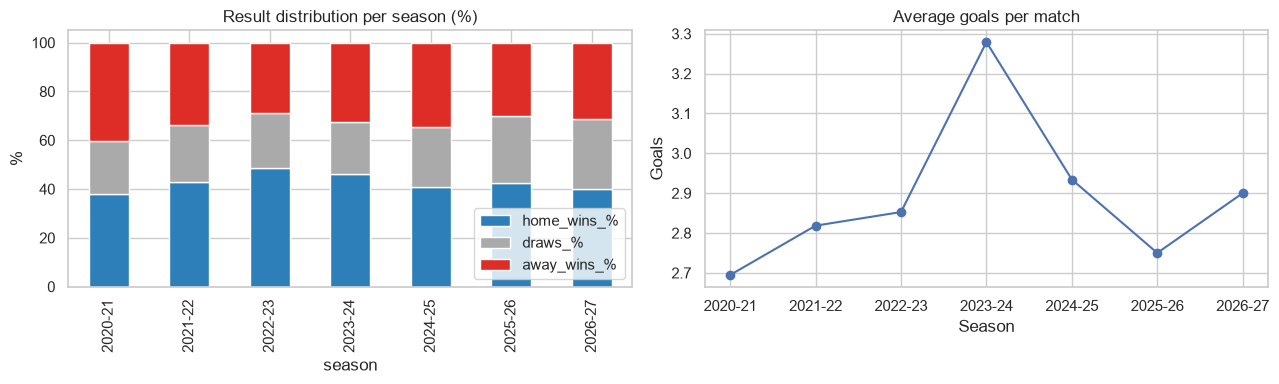

In [115]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

# (a) Result distribution per season
baselines[["home_wins_%", "draws_%", "away_wins_%"]].plot(
    kind="bar", stacked=True, ax=ax[0], color=["#2c7fb8", "#aaaaaa", "#de2d26"]
)
ax[0].set_title("Result distribution per season (%)")
ax[0].set_ylabel("%")
ax[0].legend(loc="lower right")

# (b) Goals per match per season
baselines["goals_per_match"].plot(kind="line", marker="o", ax=ax[1])
ax[1].set_title("Average goals per match")
ax[1].set_ylabel("Goals")
ax[1].set_xlabel("Season")

plt.tight_layout()
plt.show()

In [116]:
# Top scorers per season (from master_player_history, aggregated over past seasons)
top_scorers = (
    all_hist.groupby(["season_name", "player_folder_name"])["goals_scored"]
    .sum()
    .reset_index()
    .sort_values(["season_name", "goals_scored"], ascending=[True, False])
    .groupby("season_name").head(5)
)
top_scorers

,season_name,player_folder_name,goals_scored
8,2006/07,Cristiano Ronaldo_dos Santos Aveiro_326,17
9,2006/07,Cristiano Ronaldo_dos Santos Aveiro_579,17
18,2006/07,James_Milner_170,6
2,2006/07,Ashley_Young_238,5
3,2006/07,Ashley_Young_52,5
...,...,...,...
14862,2024/25,Mohamed_Salah_381,58
14500,2024/25,Alexander_Isak_499,46
14630,2024/25,Erling_Haaland_430,44
14552,2024/25,Bryan_Mbeumo_119,40


## Findings (Phase 1) — FINAL

### Baseline numbers (beat these in Phase 4)
- Majority class ("always home"): **43.0 %**
- Always-home: 43.0 % · Always-draw: 23.7 % · Always-away: 33.3 %
- Mean goals per match: 2.889
- **Bet365 1X2 opening odds: 100 % coverage across all 7 seasons** ✅
- Bookmaker-implied baseline: to be computed in Phase 4

### Data problems to fix in Phase 2

1. **Team names** — 13 mismatches E0↔Understat (underscores/long forms),
   5 mismatches E0↔FPL ("Man Utd", "Sheffield Utd", "Spurs").
   Fix: `ml/mappings.py`.

2. **Dates** — 3 formats (E0 `DD/MM/YYYY`, FPL ISO+Z, Understat
   `YYYY-MM-DD HH:MM:SS`). Unify to tz-aware UTC.

3. **`ppda` dict-strings** — parse with `ast.literal_eval` → `att/def`.

4. **`was_home`** — already `bool` ✅ (no cast needed).

5. **`season_name`** — `"2019/20"` → `"2019-20"`.

6. **FPL team IDs** — build from observed `(team, opponent_team)` pairs.

7. **Understat absent** for 2025-26 and 2026-27 → model handles NaN
   natively via XGBoost.

8. **`master_player_history` is FULL CUMULATIVE history in each folder**
   (CHECK 1): each file covers 2006/07 → its own season (15-19 seasons,
   internally clean except 3 trivial dups). Concatenating 7 folders
   creates 4,277 false duplicates. **Fix**: use ONLY the 2026-27 file,
   or dedupe on `(element_code, season_name)`.

9. **Understat files contain previous-season leakage** (CHECK 2):
   2020-21 file has 874 rows with date range 2019-08-09 → 2021-05-23 =
   57 matches from 2019-20 leaked in. **Fix**: filter by folder date
   range (e.g. `2020-08-01 → 2021-07-31`) per season.

10. **Understat has 52 unpaired dates** (only 1 team on the date) in
    2020-21 → drop rows where the home/away partner is missing.

11. **Position nomenclature** — `GK`/`GKP`, `MID`/`AM` vary → normalize.

12. **`xP_projections` unusable** — no fixture/gameweek key, 34 rows per
    player with only `(id, xP, season)`. **Drop from scope.**

13. **2026-27 `player_gw` + `gameweeks` + `player_history` are EXACT
    COPIES of 2025-26** (CHECK 3 — identical kickoff times, identical
    top-5 players, same 2,349 history rows). **Drop 2026-27 from all
    player-level modelling.** Use 2026-27 `E0` only (70 real matches).

14. **2026-27 has 0 upcoming matches** — last played 2026-10-19. §F-M3
    becomes "predict any home/away pair" (see Phase 5).

### Player identity
- `element_code` = **canonical cross-season PK**.
- `element` = per-season only → never use across seasons.
- Row key in-season = `(element_code, season_name)`.

### Age / DOB — RISK (confirmed)
Not present in any file. Needed for `F-S2`. Plan: enrich via FPL
`bootstrap-static.birth_date` (Phase 8), or proxy with "years since
first `season_name`".

### Rich feature set (bonus)
`player_gw` contains `expected_goals`, `expected_assists`,
`expected_goals_conceded`, `expected_goal_involvements`. §6.3 features
richer than the spec assumed.

### Ready for Phase 2
- [x] Team mapping approach decided (13+5 mappings)
- [x] Player PK = `element_code` confirmed
- [x] `ppda` parsing tested
- [x] Understat absence strategy chosen
- [x] All 3 verification checks passed

### J1 milestone
✅ Data unified, notebook complete, findings documented.

In [117]:
# ============ CHECK 1 — Is player_history duplicated across season folders? ============
print("=== CHECK 1: player_history duplication across folders ===")
for s in seasons:
    ph = data_loader.load_player_history(s)
    if ph is not None:
        n_total = len(ph)
        n_unique = ph[["element_code", "season_name"]].drop_duplicates().shape[0]
        n_seasons = ph["season_name"].nunique()
        n_codes = ph["element_code"].nunique()
        print(f"{s}: {n_total} rows | {n_unique} unique (code, season) | {n_codes} unique codes | {n_seasons} seasons in file")
    else:
        print(f"{s}: MISSING")

# Expected healthy: n_total == n_unique.
# If n_total > n_unique → duplicates within the same file.
# If a 2020-21 file contains seasons back to 2006/07 → it's full history, so folders duplicate each other.

=== CHECK 1: player_history duplication across folders ===
2020-21: 2764 rows | 2764 unique (code, season) | 713 unique codes | 15 seasons in file
2021-22: 2243 rows | 2243 unique (code, season) | 535 unique codes | 15 seasons in file
2022-23: 2218 rows | 2218 unique (code, season) | 532 unique codes | 16 seasons in file
2023-24: 3181 rows | 3178 unique (code, season) | 865 unique codes | 18 seasons in file
2024-25: 2316 rows | 2316 unique (code, season) | 595 unique codes | 18 seasons in file
2025-26: 2349 rows | 2346 unique (code, season) | 611 unique codes | 19 seasons in file
2026-27: 2349 rows | 2346 unique (code, season) | 611 unique codes | 19 seasons in file


In [118]:
# ============ CHECK 2 — What are the 874 Understat rows in 2020-21? ============
print("\n=== CHECK 2: Understat row count analysis 2020-21 ===")
und = data_loader.load_understat("2020-21")

print("Total rows:", len(und))
print("Unique (date, team_name, h_a):", und.drop_duplicates(["date", "team_name", "h_a"]).shape[0])
print("Duplicated (date, team_name, h_a):", und.duplicated(["date", "team_name", "h_a"]).sum())

print("\nDate range:", und["date"].min(), "→", und["date"].max())
print("Distinct dates:", und["date"].nunique())

print("\nRows per date (summary):")
print(und.groupby("date").size().describe())

print("\nDates with more than 20 teams (i.e. more than 10 matches):")
bad_dates = und.groupby("date").size()
print(bad_dates[bad_dates > 20].sort_values(ascending=False).head(10))

print("\nTeam count per date (should be even, ≤ 20):")
print(und.groupby("date")["team_name"].nunique().value_counts().sort_index())

# Expected healthy: every date has an EVEN number of unique teams ≤ 20.
# If odd or > 20 → duplicate rows or leaked data from other seasons.


=== CHECK 2: Understat row count analysis 2020-21 ===
Total rows: 874
Unique (date, team_name, h_a): 874
Duplicated (date, team_name, h_a): 0

Date range: 2019-08-09 20:00:00 → 2021-05-23 15:00:00
Distinct dates: 419

Rows per date (summary):
count   419.000
mean      2.086
std       1.158
min       1.000
25%       2.000
50%       2.000
75%       2.000
max      20.000
dtype: float64

Dates with more than 20 teams (i.e. more than 10 matches):
Series([], dtype: int64)

Team count per date (should be even, ≤ 20):
team_name
1      52
2     333
3       8
4      20
6       4
8       1
20      1
Name: count, dtype: int64


In [119]:
# ============ CHECK 3 — Is 2026-27 player_gw actually a copy of 2025-26? ============
print("\n=== CHECK 3: 2026-27 player_gw is real or a copy of 2025-26? ===")
gw_25 = data_loader.load_gameweeks("2025-26")
gw_26 = data_loader.load_gameweeks("2026-27")

print(f"2025-26 shape: {gw_25.shape} | 2026-27 shape: {gw_26.shape}")

# Are kickoff timestamps identical (proof of copy)?
same_kt = gw_25["kickoff_time"].tolist() == gw_26["kickoff_time"].tolist()
print(f"Kickoff times identical row-by-row: {same_kt}")

# What dates does the 2026-27 file claim?
print(f"2026-27 kickoff range: {gw_26['kickoff_time'].min()} → {gw_26['kickoff_time'].max()}")
print(f"2025-26 kickoff range: {gw_25['kickoff_time'].min()} → {gw_25['kickoff_time'].max()}")

# Do the top-5 player names in both seasons match?
print("\nTop 5 players in 2025-26 gameweeks:")
print(gw_25.nlargest(5, "total_points")[["name", "team", "kickoff_time", "total_points"]])

print("\nTop 5 players in 2026-27 gameweeks:")
print(gw_26.nlargest(5, "total_points")[["name", "team", "kickoff_time", "total_points"]])

# Expected: if 2026-27 is real, kickoff range ≈ 2026-08 → 2027-05 and top players differ from 2025-26.
# If it's a copy, all checks match 2025-26.


=== CHECK 3: 2026-27 player_gw is real or a copy of 2025-26? ===
2025-26 shape: (29757, 46) | 2026-27 shape: (29757, 46)
Kickoff times identical row-by-row: True
2026-27 kickoff range: 2025-08-15T19:00:00Z → 2026-05-24T15:00:00Z
2025-26 kickoff range: 2025-08-15T19:00:00Z → 2026-05-24T15:00:00Z

Top 5 players in 2025-26 gameweeks:
                          name       team          kickoff_time  total_points
8591            Jurriën Timber    Arsenal  2025-08-23T16:30:00Z            24
29078         Micky van de Ven      Spurs  2025-10-26T16:30:00Z            23
6652        Keane Lewis-Potter  Brentford  2025-12-20T15:00:00Z            21
19452  Konstantinos Mavropanos   West Ham  2026-04-10T19:00:00Z            21
2905              Eberechi Eze    Arsenal  2025-11-23T16:30:00Z            20

Top 5 players in 2026-27 gameweeks:
                          name       team          kickoff_time  total_points
8591            Jurriën Timber    Arsenal  2025-08-23T16:30:00Z            24
29078